# Eigenfaces: Recovering Humans from Ghosts

Article: [Eigenfaces: Recovering Humans from Ghosts](https://medium.com/data-science/eigenfaces-recovering-humans-from-ghosts-17606c328184)

In [1]:
import requests
import zipfile
from pathlib import Path
import os

# Configuration
use_grey_dataset_bool = (
    os.getenv("USE_GREY_DATASET", "true").strip().lower() == "true" # Default True.
)
#use_grey_dataset_bool = False # Override for debugging

number_of_images_per_row = 4
number_of_images_per_column = 4
number_of_images_to_load = 1000 # Default in the article 1000

if use_grey_dataset_bool:
    url = "https://conradsanderson.id.au/lfwcrop/lfwcrop_grey.zip"
    zip_path = Path("./data/lfwcrop_grey.zip") # Location of the ZIP dataset file
    extract_dir = Path("./data/lfwcrop_grey") # Extracted images directory
else:
    url = "https://conradsanderson.id.au/lfwcrop/lfwcrop_color.zip"
    zip_path = Path("./data/lfwcrop_color.zip") # Location of the ZIP dataset file
    extract_dir = Path("./data/lfwcrop_color") # Extracted images directory

# Download the dataset
if not zip_path.exists():
    response = requests.get(url, timeout=120)
    response.raise_for_status()

    zip_path.write_bytes(response.content)
    print(f"Downloaded: {zip_path}")
else:
    print(f"Already downloaded: {zip_path}")

# Extract the dataset
if not extract_dir.exists() or not any(extract_dir.iterdir()):
    extract_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)

    print(f"Extracted to: {extract_dir.resolve()}")
else:
    print(f"Dataset already extracted: {extract_dir.resolve()}")

file_size = zip_path.stat().st_size
#print(f"File size: {file_size:,} bytes")
print(f"File size: {file_size / 1024**2:.2f} MB")

Already downloaded: data/lfwcrop_grey.zip
Dataset already extracted: /Users/alvaro/PycharmProjects/IATD-Machine-Learning-Algorithms/data/lfwcrop_grey
File size: 48.76 MB


## Implementation

Ok! Everyone ready for implementation. First, we’ll import the required libraries. I assume you all know what they are for. I’ll focus on the explanation part of algorithms. If you have any other questions about the code, leave a response below.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import os

Then, we need a function to visualise the images from our dataset in a good-looking way. Here it is.

In [3]:
"""It helps visualising the portraits from the dataset."""
'''def plot_portraits(images, titles, h, w, n_row, n_col):
    plt.figure(figsize=(2.2 * n_col, 2.2 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.20)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        plt.title(titles[i])
        plt.xticks(())
        plt.yticks(())'''

def plot_portraits(images, titles, n_row, n_col):
    plt.figure(figsize=(2.2 * n_col, 2.2 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.20)

    for i in range(min(n_row * n_col, len(images))):
        plt.subplot(n_row, n_col, i + 1)
        image = images[i]

        if image.ndim == 2:
            plt.imshow(image, cmap="gray")
        else:
            plt.imshow(np.clip(image, 0, 1))

        plt.title(titles[i])
        plt.xticks(())
        plt.yticks(())

Let’s put it on our dataset [lfwcrop_grey.zip](https://conradsanderson.id.au/lfwcrop/lfwcrop_grey.zip). Here, I only take first 1000 of the faces because of the computational complexity but it really doesn’t matter. If you want to go full house then go for it. I also transformed images into numpy array (shaped 1000, 64, 64) for processing.

Source of the datasets: [LFWcrop Face Dataset](https://conradsanderson.id.au/lfwcrop/?utm_source=chatgpt.com)

In [4]:
#dir='lfwcrop_grey/faces'
dir = extract_dir /  ("lfwcrop_grey" if use_grey_dataset_bool else "lfwcrop_color") / "faces"

print("Working directory:", Path.cwd())
print("Expected faces folder:", (dir).resolve())
print("Folder exists:", (dir).is_dir())

Working directory: /Users/alvaro/PycharmProjects/IATD-Machine-Learning-Algorithms
Expected faces folder: /Users/alvaro/PycharmProjects/IATD-Machine-Learning-Algorithms/data/lfwcrop_grey/lfwcrop_grey/faces
Folder exists: True


PGM (Portable Graymap) is an image format designed for greyscale images. For your Eigenfaces exercise, each 64 × 64 PGM image contains 4,096 pixel values representing brightness.

In [5]:
from PIL import Image

image_paths = sorted(
    path
    for path in extract_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in {".pgm", ".ppm"}
)

if not image_paths:
    print("No PGM or PPM images found in:", extract_dir.resolve())
else:
    with Image.open(image_paths[0]) as image:
        print("File:", image_paths[0])
        print("Image dimensions:", image.size)
        print("Image mode:", image.mode)

    print(f"There are {len(image_paths)} PGM or PPM images found in: {extract_dir.resolve()}")

File: data/lfwcrop_grey/lfwcrop_grey/faces/AJ_Cook_0001.pgm
Image dimensions: (64, 64)
Image mode: L
There are 13233 PGM or PPM images found in: /Users/alvaro/PycharmProjects/IATD-Machine-Learning-Algorithms/data/lfwcrop_grey


The images array shape is (1000, 64, 64). A sample of 16 images is shown below.


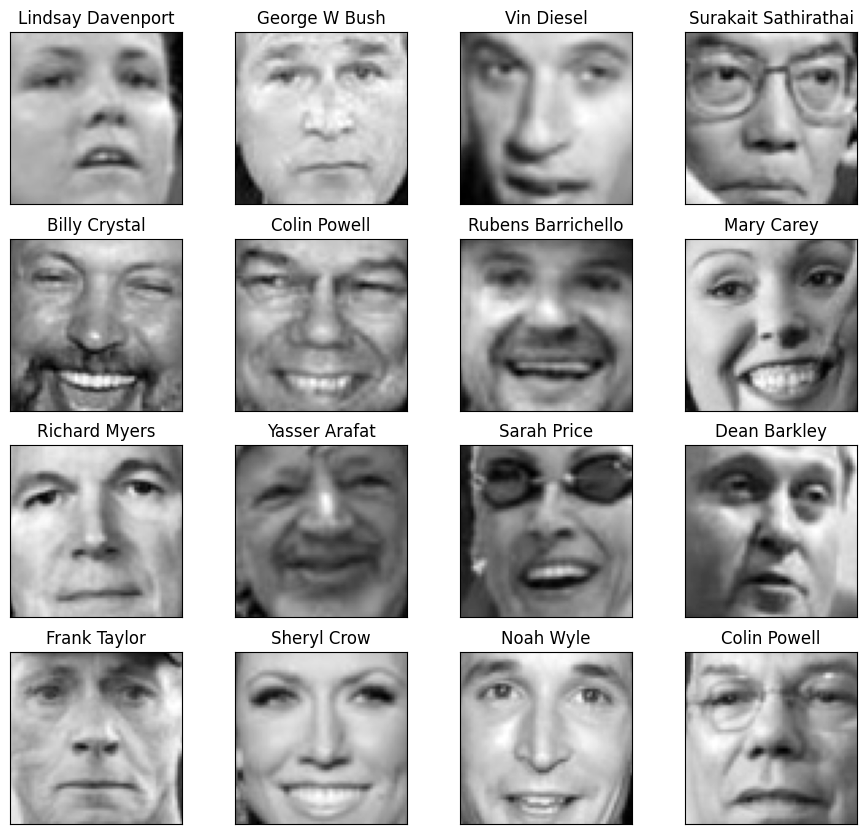

In [6]:
use_article_sorting_images=True

if use_article_sorting_images:
    celebrity_photos=os.listdir(dir)[1:(number_of_images_to_load + 1)]
    celebrity_images=[dir /  photo for photo in celebrity_photos]
    celebrity_names=[name[:name.find('0')-1].replace("_", " ") for name in celebrity_photos]
else:
    celebrity_images = image_paths[:number_of_images_to_load]
    celebrity_photos = [path.name for path in celebrity_images]

    # Example: "Aaron_Eckhart_0001.pgm" → "Aaron Eckhart"
    celebrity_names = [
        path.stem.rsplit("_", 1)[0].replace("_", " ")
        for path in celebrity_images
    ]

if use_grey_dataset_bool:
    images=np.array([plt.imread(image) for image in celebrity_images], dtype=np.float64)
    n_samples, h, w = images.shape

else:
    loaded_images = []
    for path in celebrity_images:
        image = plt.imread(path)
        if np.issubdtype(image.dtype, np.integer):
            image = image.astype(np.float64) / np.iinfo(image.dtype).max
        else:
            image = image.astype(np.float64)
        loaded_images.append(image)

    images = np.stack(loaded_images)
    n_samples, h, w = images.shape[:3]

print(f"The images array shape is {images.shape}. A sample of {number_of_images_per_row*number_of_images_per_column} images is shown below.")
plot_portraits(images, celebrity_names, n_row=number_of_images_per_row, n_col=number_of_images_per_column)

Going on, the next step is to define PCA. Its arguments are X which is vectors of images and n_pc which is the number of principal components. As a little reminder, principal components define an orthonormal basis that can extract the maximum variance in the original data. In our case, its shape is (1000, 4096) since we needed to transform the images into vectors for PCA. Then, we find the mean and subtract it from our data to center it around the origin. After that, we need to perform Singular Value Decomposition on the centered data to find those principle components called [eigenfaces](https://en.wikipedia.org/wiki/Eigenface).

$$
X = U S V^T
$$

*S matrix has the singular values along the diagonal while U and V are singular vectors*

(SVD is difficult to get and much more complex than that. For a helpful illustration, go to that [MIT OpenCourseWare video](https://www.youtube.com/watch?v=cOUTpqlX-Xs).)

```python
def pca(X, n_pc):
    n_samples, n_features = X.shape
    mean = np.mean(X, axis=0)
    centered_data = X-mean
    U, S, V = np.linalg.svd(centered_data)
    components = V[:n_pc]
    projected = U[:,:n_pc]*S[:n_pc]

    return projected, components, mean, centered_data
```

In [7]:
def pca(X: np.ndarray, n_pc: int, full_matrices: bool = True) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Reduce data to principal components using singular value decomposition.

    Parameters
    ----------
    X : numpy.ndarray of shape (n_samples, n_features)
        Input data, with one sample per row and one feature per column.
        For face images, each row contains the flattened pixels of one image.
    n_pc : int
        Number of principal components to retain. Must satisfy
        1 <= n_pc <= min(n_samples, n_features); not validated here.
    full_matrices : bool, default=True
        Passed to np.linalg.svd. If True, compute full singular-vector
        matrices: U has shape (n_samples, n_samples) and V has shape
        (n_features, n_features). If False, use reduced SVD with
        k = min(n_samples, n_features): U has shape (n_samples, k)
        and V has shape (k, n_features).
        False uses less memory for rectangular inputs and can be faster.
        Both settings compute all k singular values; this option does not
        select the number of PCA components. For valid n_pc, reduced SVD
        preserves the retained PCA subspace and explained variance,
        up to numerical precision and equivalent choices of basis.

    Returns
    -------
    projected : numpy.ndarray of shape (n_samples, n_pc)
        Coordinates (scores) of each sample along the retained components.
    components : numpy.ndarray of shape (n_pc, n_features)
        Principal directions, ordered by decreasing explained variance.
        For face images, these directions are the flattened eigenfaces.
    mean : numpy.ndarray of shape (n_features,)
        Mean feature values across all samples (the flattened mean face).
    centered_data : numpy.ndarray of shape (n_samples, n_features)
        Input data with the mean subtracted from every row.

    Notes
    -----
    Features are centered but are not scaled to unit variance.
    NumPy returns the transposed right-singular-vector matrix as V.
    With k = len(S), the full SVD satisfies
    centered_data = U[:, :k] @ np.diag(S) @ V[:k, :].
    The scores equal centered_data @ components.T.
    Reconstruct the input approximately with projected @ components + mean.

    This custom function returns arrays, not a fitted scikit-learn PCA object.
    Prints the percentage of total variance retained by the selected components.
    If all samples are identical, total variance is zero and retention is undefined.
    It does not return explained_variance_ratio_.
    """
    n_samples, n_features = X.shape

    # Subtract the mean face so PCA describes variation around it.
    mean = np.mean(X, axis=0)
    centered_data = X-mean

    # np.linalg.svd: https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html
    # Singular values in S are ordered from largest to smallest.
    # Note that SVD returns U, Sigma, and V transposed. But the original author decided to call them S instead of Sigma, and V instead of Vt.
    U, S, V = np.linalg.svd(centered_data, full_matrices=full_matrices)

    # Keep the leading directions and the corresponding sample scores.
    components = V[:n_pc] # Retain the leading eigenfaces.
    projected = U[:,:n_pc]*S[:n_pc] # Coordinates of each image along those eigenfaces. The multiplication scales each selected column of U by its corresponding singular value.

    # Variance is proportional to the squared singular values.
    total_variance = np.sum(S**2)
    retained_variance = (
        np.sum(S[:n_pc]**2) / total_variance if total_variance > 0 else np.nan
    )
    print(f"Variance retained ({n_pc} components): {retained_variance:.2%}")

    return projected, components, mean, centered_data

In [8]:
def reconstruction(
    Y: np.ndarray,
    C: np.ndarray,
    M: np.ndarray,
    h: int,
    w: int,
    image_index: int,
) -> np.ndarray:
    """Reconstruct one face using the retained PCA components and mean face.

    Parameters
    ----------
    Y : numpy.ndarray of shape (n_samples, n_features)
        Mean-centered, flattened images returned as centered_data by pca().
        These are pixel-space values, not the reduced PCA scores.
    C : numpy.ndarray of shape (n_pc, n_features)
        Orthonormal principal components returned by pca(); each row is
        a flattened eigenface.
    M : numpy.ndarray of shape (n_features,)
        Mean face returned by the same PCA fit used to obtain C.
    h : int
        Image height in pixels.
    w : int
        Image width in pixels. The product h * w must equal n_features.
    image_index : int
        Row index of the image to reconstruct in Y. Uses NumPy indexing,
        including negative indices counted from the end.

    Returns
    -------
    recovered_image : numpy.ndarray of shape (h, w)
        Reconstructed grayscale image after adding the mean face back.
        Pixel values are not clipped to the original image range.

    Notes
    -----
    First project the centered images onto C to obtain component weights.
    Then combine the selected image weights with the eigenfaces, restore
    the mean, and reshape the flattened result into an image.
    Discarded components are omitted, so reconstruction is approximate.
    This implementation computes weights for all samples on each call.
    """
    n_samples, n_features = Y.shape

    # Project each centered face onto the retained eigenfaces.
    weights = np.dot(Y, C.T)

    # Rebuild the selected centered face as a weighted sum of eigenfaces.
    centered_vector=np.dot(weights[image_index, :], C)

    # Restore the mean face and the original two-dimensional image shape.
    recovered_image=(M+centered_vector).reshape(h, w)
    return recovered_image

### How many PCA components can we retain?

There are two different limits: **the number of components the function allows** and **the number that can carry nonzero variance**.

In our code, `sample_count = images.shape[0]` is the number of images. The validation uses:

```python
limit = min(sample_count, feature_count)
```

This matches the number of singular values returned by SVD. It allows components whose variance may be zero.

After subtracting the mean image, the centered sample vectors sum to zero. This introduces a linear dependency, so at most **min(sample_count - 1, feature_count)** components can carry nonzero variance. Duplicate images or other linear dependencies can reduce this number further.

For images measuring 64 × 64 pixels:

| Number of images | Image type | Features per image | Maximum allowed by our code | Maximum with nonzero variance |
|---:|---|---:|---:|---:|
| 16 | Grayscale | 4,096 | 16 | 15 |
| 1,000 | Grayscale | 4,096 | 1,000 | 999 |
| 1,000 | RGB color | 12,288 | 1,000 | 999 |

Grayscale images have one feature per pixel. RGB images have three features per pixel: red, green, and blue.

For example, with 16 images, requesting 16 components is valid in our function, but the 16th component has zero variance apart from numerical rounding. Keeping it adds no reconstruction information.

Each principal component represents a **pattern of variation across the images**. Retaining more components with nonzero variance generally improves reconstruction quality but requires more storage.

The current validation is valid. To restrict requests to the theoretical maximum number of components with nonzero variance, we could instead use:

```python
limit = min(sample_count - 1, feature_count)
```

This alternative is still an upper bound, not a guarantee that every retained component carries nonzero variance.


In [9]:
def pca_for_components(
    images: np.ndarray,
    component_counts: list[int],
    full_matrices: bool = False,
) -> dict[int, dict[str, np.ndarray | list[str] | float]]:
    """Compute eigenface results for several component counts with one SVD.

    images must have shape (n_samples, height, width) for grayscale or
    (n_samples, height, width, channels) for color. All channels are included
    as features. Each component count must be between 1 and
    min(n_samples, number of features per image). Duplicate counts
    are combined. full_matrices is passed to NumPy SVD; False saves memory.

    Returns a dictionary keyed by component count. Each entry contains:
    P (scores), C (components), M (mean), Y (centered pixels), eigenfaces,
    eigenface_titles, and retained_variance (a fraction between 0 and 1;
    NaN when total variance is zero).

    Entries share array storage to avoid duplicating the dataset and model.
    Treat the returned arrays as read-only or copy them before modification.
    Reconstruct an entry with (P @ C + M).reshape(images.shape).
    """
    if images.ndim not in (3, 4):
        raise ValueError(
            "images must have shape (samples, height, width) or "
            "(samples, height, width, channels)"
        )
    if any(size == 0 for size in images.shape):
        raise ValueError("images must have non-empty dimensions")

    sample_count = images.shape[0]
    image_shape = images.shape[1:]
    feature_count = int(np.prod(image_shape))
    limit = min(sample_count, feature_count)
    if not component_counts or any(
        isinstance(n, (bool, np.bool_))
        or not isinstance(n, (int, np.integer))
        or not 1 <= n <= limit
        for n in component_counts
    ):
        raise ValueError(f"Provide component counts between 1 and {limit}")

    counts = sorted(set(int(n) for n in component_counts))
    X = images.reshape(sample_count, feature_count)
    M = X.mean(axis=0)
    Y = X - M

    # Compute once; smaller models use prefixes of the same decomposition.
    U, S, V = np.linalg.svd(Y, full_matrices=full_matrices)
    largest_count = max(counts)
    scores = U[:, :largest_count] * S[:largest_count]
    components = V[:largest_count].copy()
    squared_singular_values = S**2
    total_variance = squared_singular_values.sum()
    cumulative_variance = np.cumsum(squared_singular_values)

    results = {}
    for n in counts:
        C = components[:n]
        results[n] = {
            "P": scores[:, :n],
            "C": C,
            "M": M,
            "Y": Y,
            "eigenfaces": C.reshape((n,) + image_shape),
            "eigenface_titles": [f"eigenface {i}" for i in range(n)],
            "retained_variance": float(
                cumulative_variance[n - 1] / total_variance
                if total_variance > 0 else np.nan
            ),
        }
    return results

By the way, here is our mean face of all 1000 faces in the dataset. We are trying to find the features that makes individuals different than the others. I hope subtracting the mean face from everyone and maximising variance make more sense now. Look at that. Carefully! It’s a bit scary, isn’t it?

The next steps are to manipulate our images to become vectors, call PCA function and manipulate our eigenfaces to become images again.

```python
n_components = 50
X = images.reshape(n_samples, h*w)
P, C, M, Y= pca(X, n_pc=n_components)
eigenfaces = C.reshape((n_components, h, w))
eigenface_titles = ["eigenface %d" % i for i in range(eigenfaces.shape[0])]
plot_portraits(eigenfaces, eigenface_titles, h, w, 4, 4)
```

10 components: 65.99% variance retained
50 components: 85.92% variance retained
100 components: 92.47% variance retained
150 components: 95.30% variance retained
200 components: 96.85% variance retained
CPU times: user 15 s, sys: 3.43 s, total: 18.4 s
Wall time: 2.15 s


'recovered_images_50 = (result["P"] @ result["C"] + result["M"]).reshape(images.shape)\nplot_portraits(recovered_images_50, celebrity_names, h, w, 4, 4)'

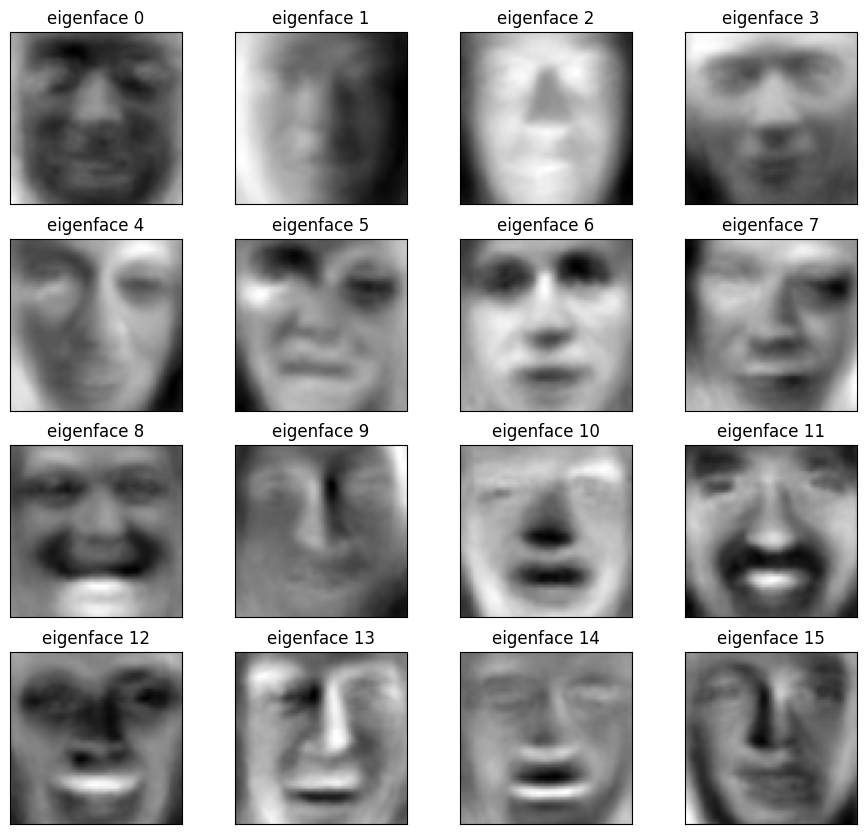

In [10]:
%%time

'''
n_components = 50
# Re 'full_matrices', the article default is True. But False is faster.
# For n_components = 50 True takes 4 seconds and False 3-4 seconds.
full_matrices=True
X = images.reshape(n_samples, h*w)
P, C, M, Y= pca(X, n_pc=n_components, full_matrices=full_matrices)
eigenfaces = C.reshape((n_components, h, w))
eigenface_titles = ["eigenface %d" % i for i in range(eigenfaces.shape[0])]
plot_portraits(eigenfaces, eigenface_titles, h, w, 4, 4)

# Compare actual NPZ file sizes, serialized in memory without writing files.
# This uses the custom PCA results P, C, M from the cell above.
# Only scores, components, mean, and image shape are needed for reconstruction:
# reconstructed = (P @ C + M).reshape(-1, h, w)
# Do not store X, Y, or reconstructed images in the PCA archive.
original_arrays = {"images": X, "image_shape": np.array([h, w])}
pca_arrays = {
    "scores": P,
    "components": C,
    "mean": M,
    "image_shape": np.array([h, w]),
}

for label, save_function in [
    ("Uncompressed NPZ", np.savez),
    ("Compressed NPZ", np.savez_compressed),
]:
    with BytesIO() as original_buffer, BytesIO() as pca_buffer:
        save_function(original_buffer, **original_arrays)
        save_function(pca_buffer, **pca_arrays)
        original_bytes = original_buffer.tell()
        pca_bytes = pca_buffer.tell()

    saved_bytes = original_bytes - pca_bytes
    saved_percentage = 100 * saved_bytes / original_bytes
    print(f"{label} ({P.shape[1]} components):")
    print(f"  Original: {original_bytes / 1024**2:.2f} MiB")
    print(f"  PCA:      {pca_bytes / 1024**2:.2f} MiB")
    print(f"  Saved:    {saved_bytes / 1024**2:.2f} MiB ({saved_percentage:.2f}%)")
    print()

print("Comparison uses the current array dtypes, not the downloaded image files.")
print("PCA reconstruction is lossy. Negative savings mean a larger archive.")
'''

pca_results = pca_for_components(images, [10, 50, 100, 150, 200])

for count, result in pca_results.items():
    print("{} components: {:.2%} variance retained".format(count, result["retained_variance"]))

# Select any stored model for plotting or reconstruction.
if use_grey_dataset_bool:
    result = pca_results[50]
    plot_portraits(
        result["eigenfaces"], result["eigenface_titles"], n_row=number_of_images_per_row, n_col=number_of_images_per_column
    )
else:
    result = pca_results[50]
    eigenfaces = result["eigenfaces"]

    # Find each eigenface's minimum and maximum across all pixels/channels.
    axes = tuple(range(1, eigenfaces.ndim))
    minimum = eigenfaces.min(axis=axes, keepdims=True)
    maximum = eigenfaces.max(axis=axes, keepdims=True)

    display_eigenfaces = np.divide(
        eigenfaces - minimum,
        maximum - minimum,
        out=np.zeros_like(eigenfaces),
        where=(maximum - minimum) != 0,
    )

    plot_portraits(
        display_eigenfaces,
        result["eigenface_titles"],
        n_row=number_of_images_per_row,
        n_col=number_of_images_per_column,
    )
'''recovered_images_50 = (result["P"] @ result["C"] + result["M"]).reshape(images.shape)
plot_portraits(recovered_images_50, celebrity_names, h, w, 4, 4)'''

### Compressed and uncompressed NPZ

An **NPZ file** is a ZIP archive containing multiple NumPy arrays. For PCA, we store the scores, principal components, and mean image needed for reconstruction.

| | Uncompressed NPZ | Compressed NPZ |
|---|---|---|
| NumPy function | `np.savez()` | `np.savez_compressed()` |
| Storage method | Packages arrays without compression | Compresses arrays using ZIP DEFLATE |
| File size | Usually larger | Usually smaller |
| Saving time | Usually faster | Requires extra computation |
| Array values | Preserved exactly | Preserved exactly |

```python
# Save without compression.
np.savez("faces.npz", scores=P, components=C, mean=M)

# Save with lossless compression.
np.savez_compressed(
    "faces_compressed.npz",
    scores=P,
    components=C,
    mean=M,
)
```

Both formats load using `np.load()`:

```python
with np.load("faces_compressed.npz") as data:
    scores = data["scores"]
    components = data["components"]
    mean = data["mean"]
```

**NPZ compression is lossless:** loading either file restores the stored arrays exactly.

**PCA reduction can be lossy:** discarding components with nonzero variance removes information, making reconstructed images approximate.

Our storage comparison measures the original arrays and PCA representation using the same file format. Savings depend on both the number of retained components and how well the arrays compress. A compressed PCA archive can therefore be larger than the compressed original arrays, producing a negative savings percentage.

In [11]:
%%time
from io import BytesIO
import pandas as pd
from IPython.display import display

# Measure serialized sizes in memory; no files are written.
# Use the same images supplied to pca_for_components().
image_shape = np.array(images.shape[1:])
original_arrays = {
    "images": images.reshape(len(images), -1),
    "image_shape": image_shape,
}
comparison_rows = []

for label, save_function in [
    ("Uncompressed NPZ", np.savez),
    ("Compressed NPZ", np.savez_compressed),
]:
    # Serialize the original dataset only once per format.
    with BytesIO() as original_buffer:
        save_function(original_buffer, **original_arrays)
        original_bytes = original_buffer.tell()

    for count, result in sorted(pca_results.items()):
        # These arrays are sufficient to reconstruct the images.
        # Exclude centered data and reconstructed images from the archive.
        with BytesIO() as pca_buffer:
            save_function(
                pca_buffer,
                scores=result["P"],
                components=result["C"],
                mean=result["M"],
                image_shape=image_shape,
            )
            pca_bytes = pca_buffer.tell()

        saved_bytes = original_bytes - pca_bytes
        comparison_rows.append({
            "Format": label,
            "Components": count,
            "Variance retained (%)": 100 * result["retained_variance"],
            "Original (MiB)": original_bytes / 1024**2,
            "PCA (MiB)": pca_bytes / 1024**2,
            "Saved (MiB)": saved_bytes / 1024**2,
            "Saved (%)": 100 * saved_bytes / original_bytes,
        })

# Keep numeric values available for later analysis or plotting.
storage_comparison = pd.DataFrame(comparison_rows)
display(storage_comparison.round(2))
print("Sizes compare current NumPy arrays, not downloaded image files.")
print("PCA reconstruction is lossy. Negative savings mean a larger archive.")


,Format,Components,Variance retained (%),Original (MiB),PCA (MiB),Saved (MiB),Saved (%)
0,Uncompressed NPZ,10,65.99,31.25,0.42,30.83,98.65
1,Uncompressed NPZ,50,85.92,31.25,1.98,29.27,93.68
2,Uncompressed NPZ,100,92.47,31.25,3.92,27.33,87.46
3,Uncompressed NPZ,150,95.30,31.25,5.86,25.39,81.24
4,Uncompressed NPZ,200,96.85,31.25,7.81,23.44,75.01
5,Compressed NPZ,10,65.99,4.90,0.39,4.51,92.12
6,Compressed NPZ,50,85.92,4.90,1.88,3.02,61.71
7,Compressed NPZ,100,92.47,4.90,3.74,1.16,23.68
8,Compressed NPZ,150,95.30,4.90,5.60,-0.70,-14.35
9,Compressed NPZ,200,96.85,4.90,7.46,-2.57,-52.38


Sizes compare current NumPy arrays, not downloaded image files.
PCA reconstruction is lossy. Negative savings mean a larger archive.
CPU times: user 2.21 s, sys: 74 ms, total: 2.29 s
Wall time: 2.04 s


First parameter named n_components determines how many eigenfaces we want to create. Those are our principal components from which we will recover our data that is human face. Changing it won’t change this table unless it is less than 16. However, I can guarantee there are only 50 images that we can trust rather than 1000 as it was the case at the beginning. (eigenfaces.shape = (50, 64, 64))

```python
def reconstruction(Y, C, M, h, w, image_index):
    n_samples, n_features = Y.shape
    weights = np.dot(Y, C.T)
    centered_vector=np.dot(weights[image_index, :], C)
    recovered_image=(M+centered_vector).reshape(h, w)
    return recovered_image
recovered_images=[reconstruction(Y, C, M, h, w, i) for i in range(len(images))]
plot_portraits(recovered_images, celebrity_names, h, w, n_row=4, n_col=4)
```

For reconstruction, we will use those eigenfaces. Each face is a weighted combination of those eigenfaces as you might say. To find weights, we should dot multiply our centered data and eigenfaces. Then, we should weight eigenfaces which gives us the centered face and add it up to the mean face again. After all, we are ready to take a look at the recovered faces compared to original ones.

CPU times: user 340 ms, sys: 592 ms, total: 932 ms
Wall time: 137 ms


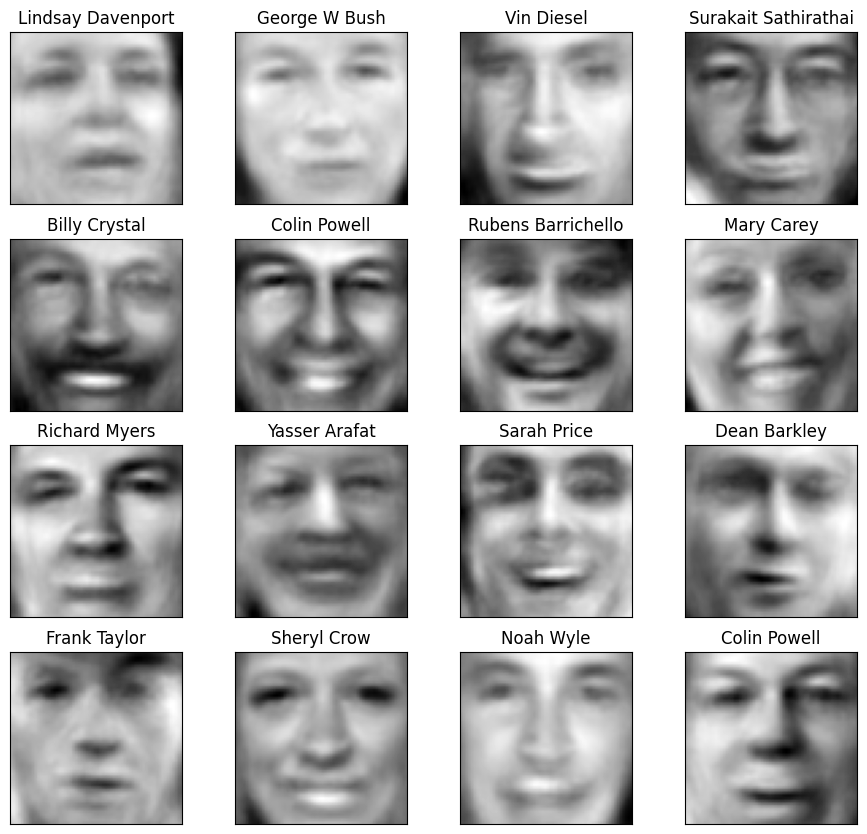

In [12]:
%%time

'''
# The original code below is VERY slow (aprox 20 seconds using 50 components)
# recovered_images=[reconstruction(Y, C, M, h, w, i) for i in range(len(images))]
# The code below is faster than the original code. It reconstructs all faces at once using the scores already computed. For 50 components, it takes between 103 to 722 ms (so less than a second).
recovered_images = (P @ C + M).reshape(n_samples, h, w)
plot_portraits(recovered_images, celebrity_names, h, w, n_row=4, n_col=4)
'''

def plot_reconstructed(n_pca: int) -> None:
    result = pca_results[n_pca]
    recovered_images = (
        result["P"] @ result["C"] + result["M"]
    ).reshape(images.shape) # .reshape(images.shape) restores the reconstructed data to the same dimensions as the original images.

    plot_portraits(
        recovered_images, celebrity_names,
        n_row=number_of_images_per_row, n_col=number_of_images_per_column,
    )

plot_reconstructed(50)

Wow! Not looking good! But, don’t forget we came from 1000 x 64 x 64 to 50 x 64 x 64. In this way, we get to keep 20 times less data than before. Still, I won’t fool anybody. Those are not good enough. It is clear we still have some important principal components we took out. Let’s see what we can do. I’ll try to use the first 100 components.

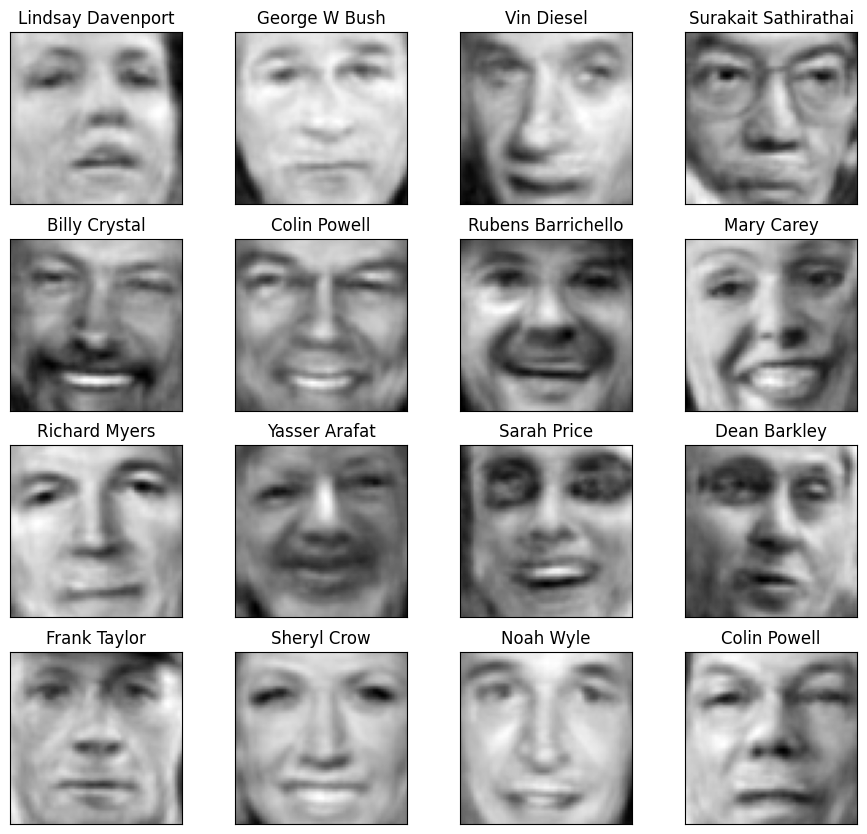

In [13]:
plot_reconstructed(150)

Getting better but still, not good enough. 250…

*I used 200 instead of the 250 from the article*

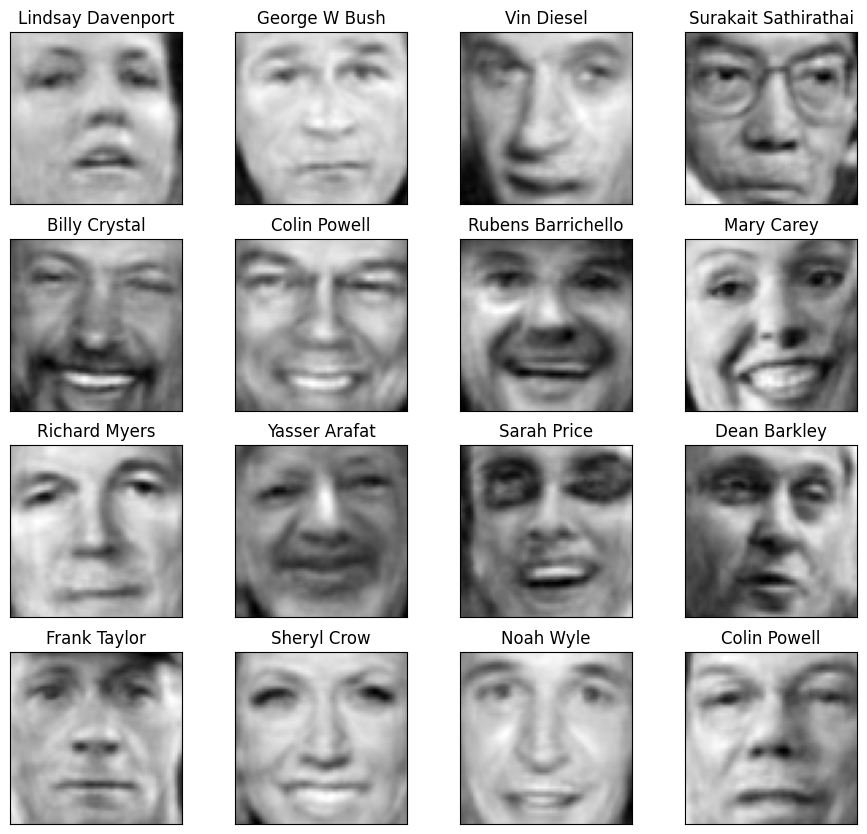

In [14]:
plot_reconstructed(200)

This one is totally satisfying for me. With only quarter of what we have we recovered totally distinguishable faces. It’s totally pointless but you can actually use 1000 eigenface components and get the exact original results. Just to show you that, I’ll run some computation and space complexity.

Still running… Hold on… It’s coming.

The results have come. Pretty sweet!!!

---

This post actually showed you having good enough information with very small size of data and this is one of our most important expectations from machine learning. I hope you see something beyond this application and start thinking about new innovations. I stated the references as I used or above.

Once again, hope you enjoyed my post. Don’t hesitate to ask your questions about it or give any type of feedback.

Cheers,

Nev

## Below is an extra using SKLearn PCA

Components retained: 143
Variance retained: 95.00%
CPU times: user 12.6 s, sys: 4.29 s, total: 16.9 s
Wall time: 2.44 s


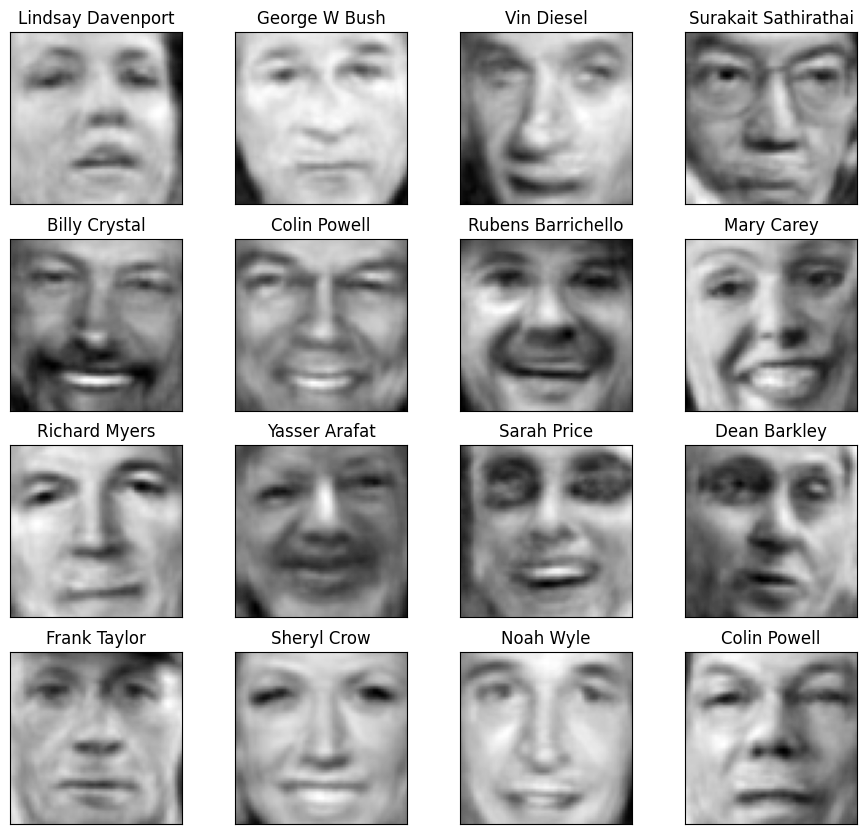

In [15]:
%%time

from sklearn.decomposition import PCA

X = images.reshape(n_samples, -1)

pca = PCA(n_components=0.95, svd_solver="full")
X_pca = pca.fit_transform(X)
reconstructed_images = pca.inverse_transform(X_pca).reshape(images.shape)

print(f"Components retained: {pca.n_components_}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.2%}")
plot_portraits(reconstructed_images, celebrity_names, n_row=number_of_images_per_row, n_col=number_of_images_per_column)

Components retained: 372
Variance retained: 99.00%
CPU times: user 12.6 s, sys: 4.04 s, total: 16.7 s
Wall time: 1.84 s


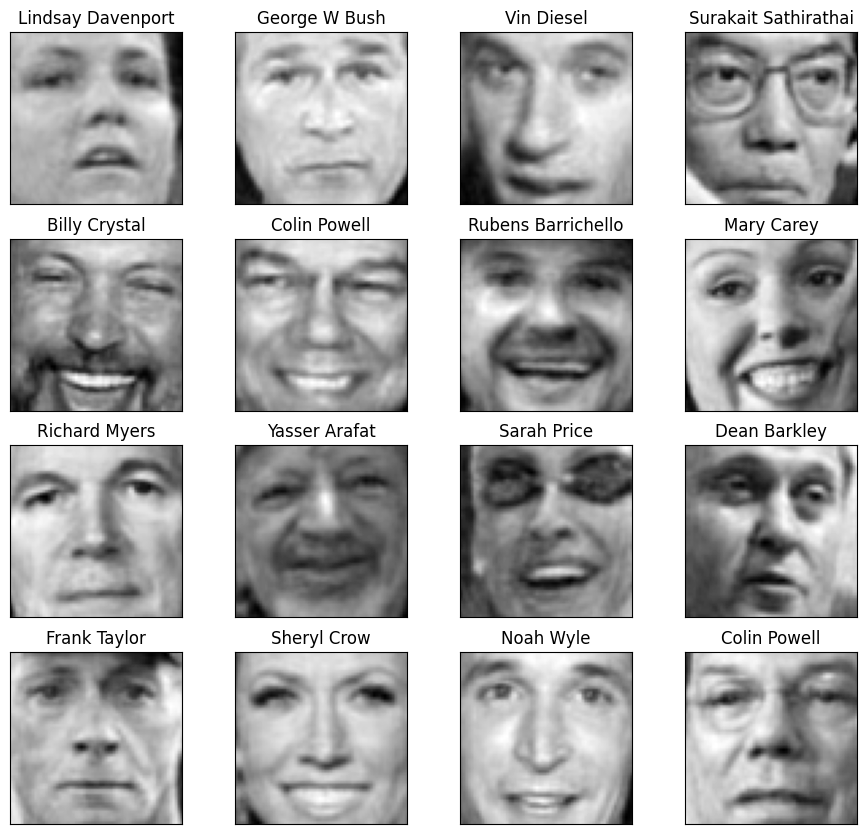

In [16]:
%%time

pca = PCA(n_components=0.99, svd_solver="full")
X_pca = pca.fit_transform(X)
reconstructed_images = pca.inverse_transform(X_pca).reshape(images.shape)

print(f"Components retained: {pca.n_components_}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.2%}")
plot_portraits(reconstructed_images, celebrity_names, n_row=number_of_images_per_row, n_col=number_of_images_per_column)

Variance retained: 99.00%


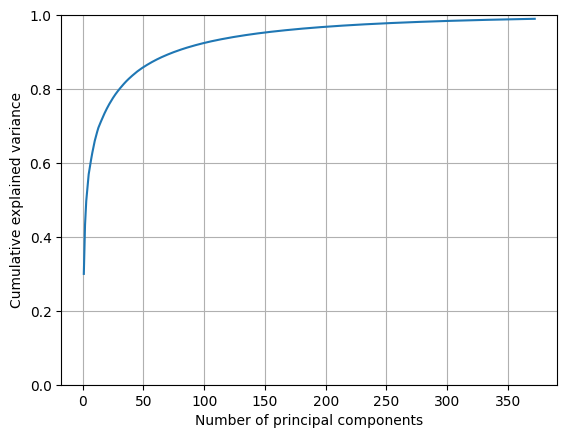

In [17]:
retained_variance = np.sum(pca.explained_variance_ratio_)
print(f'Variance retained: {retained_variance:.2%}')

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure()
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.ylim(0, 1)
plt.grid()
plt.show()